# 13  -  Observational Trigger: Wind Exposure & Population

Evaluates the observational trigger for the Philippines AA Storms programme using historical IBTrACS track data.

For each historical WP typhoon (1980-2024) the notebook:
1. Detects storms that made **landfall** in the target regions — defined as a track segment crossing from outside into the target-region boundary
2. Builds asymmetric 64-kt wind footprints using observed radii (mean-infilled where missing)
3. Clips to the **four target regions** (Regions II, III, V, VIII / PH02, PH03, PH05, PH08)
4. Counts exposed admin-3 municipalities and sums WorldPop population
5. Calculates return periods for a sweep of population-exposure thresholds
6. Produces a year-by-year activation timeline

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import ocha_stratus as stratus
from shapely.geometry import LineString, Polygon
from shapely.ops import unary_union
from rasterstats import zonal_stats

In [30]:
# ── Constants ─────────────────────────────────────────────────────────────────
# IBTrACS WP wind_speed is JMA 10-min sustained in knots.
#
# KT_THRESHOLD is the minimum *centre* wind for a track point to be included.
# At 64 kt centre, the 64-kt radius is degenerate (≈ 0), so results are noisy.
# 100 kt = PAGASA super typhoon (≥ 185 kph 10-min sustained). At this intensity
# the 64-kt wind field extends well outward and is reliably observed in IBTrACS.
KT_THRESHOLD   = 100.0       # minimum centre-wind (kt) to include a track point
CRS_METRIC     = "EPSG:32651"  # UTM Zone 51N
HEADER_COLOR   = "#14805a"   # OCHA green
START_YEAR     = 1980
END_YEAR       = 2024

# Target regions
TARGET_REGIONS = ["PH02", "PH03", "PH05", "PH08"]

CONTAINER = "projects"
STAGE     = "dev"

print(f"KT threshold : {KT_THRESHOLD} kt ({KT_THRESHOLD * 1.852:.0f} km/h 10-min)  -  PAGASA super typhoon")
print(f"Record       : {START_YEAR}-{END_YEAR}  ({END_YEAR - START_YEAR + 1} years)")
print(f"Target regions: {TARGET_REGIONS}")

KT threshold : 100.0 kt (185 km/h 10-min)  -  PAGASA super typhoon
Record       : 1980-2024  (45 years)
Target regions: ['PH02', 'PH03', 'PH05', 'PH08']


In [31]:
# ── Admin boundaries ─────────────────────────────────────────────────────────
phl_admin_1 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=1)
phl_admin_3 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=3)

pcode_col = [c for c in phl_admin_1.columns if "src" in c.lower()][0]
target_regions_gdf = phl_admin_1[phl_admin_1[pcode_col].isin(TARGET_REGIONS)].copy()
target_union = unary_union(target_regions_gdf.geometry)
print(f"Target regions: {target_regions_gdf['adm1_name'].tolist()}")

# Identify the admin-1 pcode column in admin-3 for filtering
adm1_pcode_col_3 = [c for c in phl_admin_3.columns if "adm1" in c.lower() and "src" in c.lower()]
print(f"Admin-3 columns: {list(phl_admin_3.columns)}")

Target regions: ['Region II (Cagayan Valley)', 'Region III (Central Luzon)', 'Region V (Bicol Region)', 'Region VIII (Eastern Visayas)']
Admin-3 columns: ['fid', 'adm3_id', 'adm3_src', 'adm3_name', 'adm3_name1', 'adm3_name2', 'adm2_id', 'adm2_src', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm1_id', 'adm1_src', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm0_id', 'adm0_src', 'adm0_name', 'adm0_name1', 'adm0_name2', 'src_lvl', 'src_lang', 'src_lang1', 'src_lang2', 'src_date', 'src_update', 'src_name', 'src_name1', 'src_lic', 'src_url', 'src_grp', 'iso_cd', 'iso_2', 'iso_3', 'iso_3_grp', 'region3_cd', 'region3_nm', 'region2_cd', 'region2_nm', 'region1_cd', 'region1_nm', 'status_cd', 'status_nm', 'wld_date', 'wld_update', 'wld_view', 'wld_notes', 'geometry']


In [32]:
# ── Filter admin-3 to target regions ─────────────────────────────────────────
# Spatial join: keep admin-3 municipalities that fall within the target union
admin3_target = phl_admin_3[phl_admin_3.intersects(target_union)].copy()
admin3_target_proj = admin3_target.to_crs(CRS_METRIC)
print(f"All admin-3 : {len(phl_admin_3):,} municipalities")
print(f"In target regions: {len(admin3_target):,} municipalities")

All admin-3 : 1,641 municipalities
In target regions: 526 municipalities


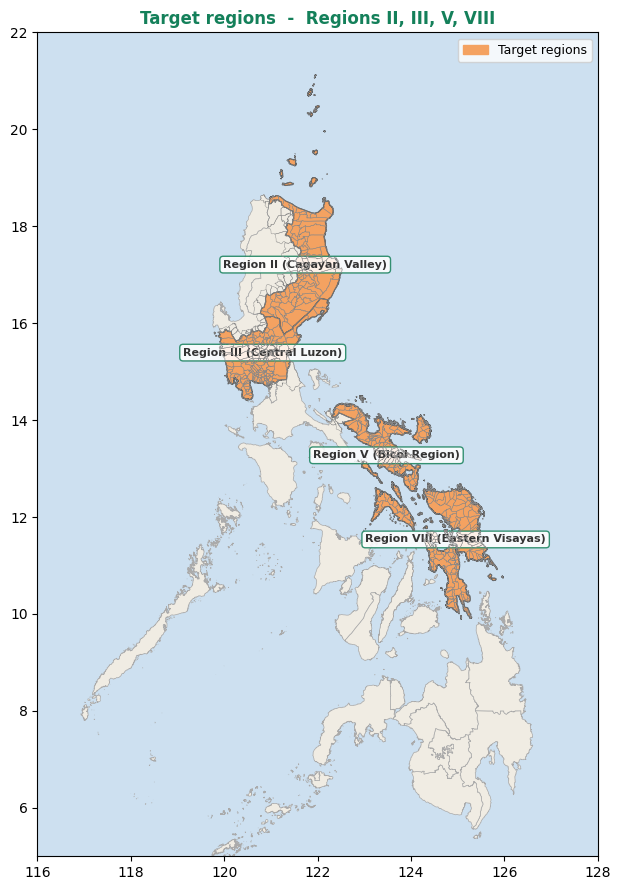

In [33]:
# ── Map: target regions with admin-3 outlines ─────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 9))
ax.set_facecolor("#cde0f0")
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5, zorder=2)
target_regions_gdf.plot(ax=ax, color="#f4a261", edgecolor="#555", linewidth=0.8, zorder=3)
admin3_target.plot(ax=ax, color="none", edgecolor="#888", linewidth=0.3, zorder=4)
for _, row in target_regions_gdf.iterrows():
    c = row.geometry.centroid
    ax.annotate(
        row["adm1_name"], xy=(c.x, c.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="#333",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=HEADER_COLOR, alpha=0.85),
    )
ax.set_xlim(116, 128); ax.set_ylim(5, 22)
ax.set_title("Target regions  -  Regions II, III, V, VIII",
             fontsize=12, fontweight="bold", color=HEADER_COLOR)
ax.legend(handles=[mpatches.Patch(color="#f4a261", label="Target regions")], fontsize=9)
plt.tight_layout()
plt.show()

In [34]:
# ── WorldPop raster ───────────────────────────────────────────────────────────
global_pop_raster = stratus.open_blob_cog(
    blob_name="worldpop/pop_count/global_pop_2026_CN_1km_R2025A_UA_v1.tif",
    stage="dev",
    container_name="raster",
)

minx, miny, maxx, maxy = admin3_target.total_bounds
pop_target = global_pop_raster.rio.clip_box(
    minx=minx - 0.1, miny=miny - 0.1,
    maxx=maxx + 0.1, maxy=maxy + 0.1,
)
print(f"Clipped raster shape: {pop_target.shape}  CRS: {pop_target.rio.crs}")

# Expose these for reuse in later cells (footprint zonal_stats and per-region breakdown)
pop_array     = pop_target.values.squeeze().astype(float)
pop_transform = pop_target.rio.transform()
nodata_val    = pop_target.rio.nodata

# Per-municipality population  -  feeds the case-study map below
target_stats = zonal_stats(
    admin3_target.to_crs(pop_target.rio.crs),
    pop_array, affine=pop_transform,
    stats=["sum"], nodata=nodata_val, all_touched=True,
)

# Total population of the target regions.
# Do NOT sum `target_stats`: `admin3_target` is built with
# .intersects(target_union), so it also admits NCR / CAR / Region I /
# Region IV-A municipalities that merely touch the boundary (NCR alone adds
# 5.1M), and all_touched=True double-counts boundary pixels across 1,000+
# polygons. That route gives 42,324,903. Sum the four region polygons instead.
_region_stats = zonal_stats(
    target_regions_gdf.to_crs(pop_target.rio.crs),
    pop_array, affine=pop_transform,
    stats=["sum"], nodata=nodata_val, all_touched=True,
)
total_pop = int(round(sum(s["sum"] or 0 for s in _region_stats)))
print(f"Total population in target regions: {total_pop:,.0f}")

# Per-municipality population  -  used only for the case-study map (cell 19)
admin3_target_pop = admin3_target.copy()
admin3_target_pop["population"] = [
    int(round(s["sum"])) if s["sum"] is not None else 0 for s in target_stats
]

Clipped raster shape: (1, 1372, 767)  CRS: EPSG:4326
Total population in target regions: 29,275,856


In [35]:
# ── IBTrACS track data ────────────────────────────────────────────────────────
def fetch_ibtracs(start_date, end_date):
    query = f"""
    SELECT *
    FROM storms.ibtracs_tracks_geo
    WHERE basin = 'WP'
      AND valid_time BETWEEN '{start_date}' AND '{end_date}'
    """
    return gpd.read_postgis(
        query, stratus.get_engine(stage="prod"), geom_col="geometry"
    )

tracks_hist = fetch_ibtracs(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
print(f"Track points : {len(tracks_hist):,}")
print(f"Date range   : {tracks_hist['valid_time'].min().date()} → {tracks_hist['valid_time'].max().date()}")
print(f"Unique storms: {tracks_hist['storm_id'].nunique()}")
print(f"Columns      : {list(tracks_hist.columns)}")

Track points : 71,673
Date range   : 1980-04-05 → 2024-12-25
Unique storms: 1127
Columns      : ['sid', 'point_id', 'storm_id', 'valid_time', 'provider', 'basin', 'nature', 'wind_speed', 'pressure', 'max_wind_radius', 'last_closed_isobar_radius', 'last_closed_isobar_pressure', 'gust_speed', 'quadrant_radius_34', 'quadrant_radius_50', 'quadrant_radius_64', 'usa_quadrant_radius_34', 'usa_quadrant_radius_50', 'usa_quadrant_radius_64', 'geometry']


In [36]:
# ── Landfall detection ────────────────────────────────────────────────────────
# A storm is considered to have made landfall when a consecutive 6-hourly track
# segment crosses from outside into the target-region boundary.
# Landfall is detected on the full track (no wind threshold), then the wind
# footprint analysis (next cell) is restricted to landfall storms only.

landfall_storm_ids = set()

for storm_id, grp in tracks_hist.sort_values("valid_time").groupby("storm_id"):
    grp = grp.reset_index(drop=True)
    for i in range(len(grp) - 1):
        p0, p1 = grp.iloc[i], grp.iloc[i + 1]
        seg = LineString([
            (p0.geometry.x, p0.geometry.y),
            (p1.geometry.x, p1.geometry.y),
        ])
        if seg.intersects(target_union):
            landfall_storm_ids.add(storm_id)
            break

print(f"Storms with landfall in target regions: {len(landfall_storm_ids)}"
      f"  (out of {tracks_hist['storm_id'].nunique()} total WP storms)")

Storms with landfall in target regions: 256  (out of 1127 total WP storms)


In [37]:
# ── Parse 64-kt wind radii ────────────────────────────────────────────────────
def parse_radii(val):
    if val is None:
        return None
    parts = str(val).strip("{}").split(",")
    vals = []
    for p in parts:
        try:
            v = float(p.strip())
            vals.append(np.nan if np.isnan(v) else v)
        except ValueError:
            vals.append(np.nan)
    return vals if any(not np.isnan(v) for v in vals) else None


def wind_polygon_utm(x, y, radii_nm):
    nm2m = 1852.0
    valid = [r * nm2m for r in radii_nm if not np.isnan(r)]
    fill  = float(np.mean(valid))
    rm    = [r * nm2m if not np.isnan(r) else fill for r in radii_nm]
    pts = []
    for deg in np.linspace(0, 360, 360, endpoint=False):
        if   deg <  90: r = rm[0]
        elif deg < 180: r = rm[1]
        elif deg < 270: r = rm[2]
        else:           r = rm[3]
        rad = np.radians(90 - deg)
        pts.append((x + r * np.cos(rad), y + r * np.sin(rad)))
    poly = Polygon(pts)
    return poly if poly.is_valid else poly.buffer(0)


# Detect the 64-kt radius columns (PostgreSQL array strings)
r64_cols = sorted([c for c in tracks_hist.columns if "radius_64" in c.lower()])
print("64-kt radius columns:")
for col in r64_cols:
    n_valid = tracks_hist[col].apply(lambda v: parse_radii(v) is not None).sum()
    print(f"  {col}: {n_valid:,} / {len(tracks_hist):,} valid  ({n_valid/len(tracks_hist)*100:.1f}%)")

64-kt radius columns:
  quadrant_radius_64: 0 / 71,673 valid  (0.0%)
  usa_quadrant_radius_64: 4,877 / 71,673 valid  (6.8%)


In [38]:
# ── Mean-infill radii ─────────────────────────────────────────────────────────
# Identify which 64-kt column has the best coverage and use it
best_col = max(r64_cols, key=lambda c: tracks_hist[c].apply(lambda v: parse_radii(v) is not None).sum())
tracks_hist["_radii_64"] = tracks_hist[best_col].apply(parse_radii)
print(f"Using column: {best_col}")

valid_radii = tracks_hist["_radii_64"].dropna().tolist()
mean_radii  = [
    float(np.nanmean([r[i] for r in valid_radii])) for i in range(4)
]
print("Mean 64-kt radii used as infill (NE / SE / SW / NW):")
print("  " + " / ".join(f"{r:.0f} nm" for r in mean_radii))

Using column: usa_quadrant_radius_64
Mean 64-kt radii used as infill (NE / SE / SW / NW):
  41 nm / 38 nm / 35 nm / 38 nm


In [39]:
# ── Build wind footprints clipped to target regions ───────────────────────────
pts = gpd.GeoDataFrame(
    tracks_hist[
        (tracks_hist["wind_speed"] >= KT_THRESHOLD) &
        (tracks_hist["storm_id"].isin(landfall_storm_ids))
    ].copy(),
    geometry="geometry", crs="EPSG:4326",
).to_crs(CRS_METRIC)

target_union_proj = target_regions_gdf.to_crs(CRS_METRIC).union_all()

print(f"Track points ≥ {KT_THRESHOLD:.0f} kt (landfall storms only) : {len(pts):,}")
n_obs    = pts["_radii_64"].notna().sum()
n_filled = pts["_radii_64"].isna().sum()
print(f"  Observed radii : {n_obs:,} ({n_obs/len(pts)*100:.1f}%)" if len(pts) else "  (no points)")
print(f"  Mean-filled    : {n_filled:,} ({n_filled/len(pts)*100:.1f}%)" if len(pts) else "")

polys = []
for _, row in pts.iterrows():
    radii = row["_radii_64"] if row["_radii_64"] is not None else mean_radii
    poly  = wind_polygon_utm(row.geometry.x, row.geometry.y, radii)
    if poly is not None:
        polys.append({"storm_id": row["storm_id"], "geometry": poly})

wind_polys = gpd.GeoDataFrame(polys, crs=CRS_METRIC)

# Dissolve to one footprint per storm, then clip to target regions
footprints = wind_polys.dissolve(by="storm_id").reset_index()[["storm_id", "geometry"]]
footprints["geometry"] = footprints["geometry"].intersection(target_union_proj)
footprints = footprints[~footprints["geometry"].is_empty].copy()
print(f"Storms with target-region exposure (landfall only): {len(footprints):,}")

Track points ≥ 100 kt (landfall storms only) : 240
  Observed radii : 124 (51.7%)
  Mean-filled    : 116 (48.3%)
Storms with target-region exposure (landfall only): 24


In [40]:
# ── Spatial join: which target-region municipalities were exposed? ─────────────
joined = gpd.sjoin(admin3_target_proj, footprints, how="inner", predicate="intersects")

muni_count = (
    joined.groupby("storm_id")
    .apply(lambda x: x.index.nunique(), include_groups=False)
    .reset_index(name="n_munis")
)

# Max wind speed and year per storm
storm_meta = (
    tracks_hist.groupby("storm_id")
    .agg(max_wind_kt=("wind_speed", "max"))
    .reset_index()
)
storm_meta["max_wind_kmh"] = (storm_meta["max_wind_kt"] * 1.852).round(1)
storm_meta["name"] = storm_meta["storm_id"].str.split("_").str[0].str.capitalize()
storm_meta["year"] = storm_meta["storm_id"].str.extract(r"_wp_(\d{4})$")

muni_count = muni_count.merge(storm_meta, on="storm_id")

# Population exposed: intersect the actual wind footprint with the population raster
# (counts only pixels inside the 64-kt wind area, not entire municipality populations)
footprints_raster_crs = footprints.to_crs(pop_target.rio.crs).reset_index(drop=True)
fp_stats = zonal_stats(
    footprints_raster_crs,
    pop_array, affine=pop_transform,
    stats=["sum"], nodata=nodata_val, all_touched=True,
)
fp_pop = pd.DataFrame({
    "storm_id": footprints["storm_id"].values,
    "population_exposed": [
        int(round(s["sum"])) if s["sum"] is not None else 0 for s in fp_stats
    ],
})
muni_count = muni_count.merge(fp_pop, on="storm_id", how="left")
muni_count["population_exposed"] = muni_count["population_exposed"].fillna(0).astype(int)

exposure = (
    muni_count[["storm_id", "name", "year", "max_wind_kmh", "n_munis", "population_exposed"]]
    .sort_values("population_exposed", ascending=False)
    .reset_index(drop=True)
)
exposure.index += 1
print(f"Storms with target-region exposure: {len(exposure)}")
print(f"Total years: {exposure['year'].dropna().nunique()}")

Storms with target-region exposure: 24
Total years: 18


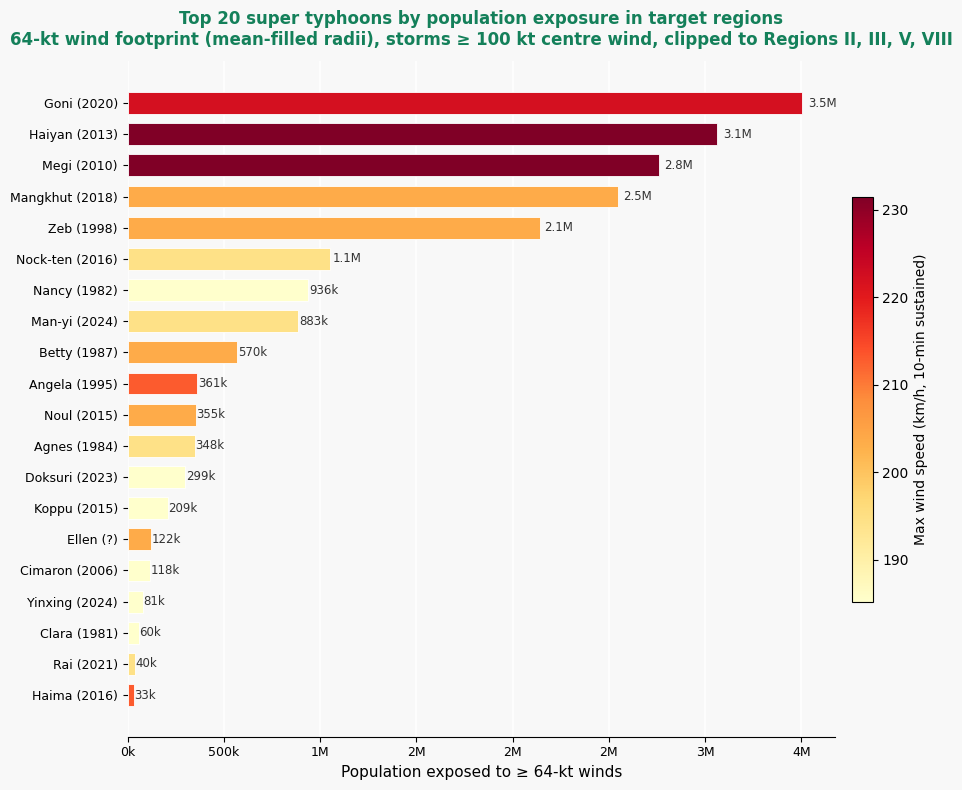

In [41]:
# ── Top 20 storms by population exposed ──────────────────────────────────────
TOP_N = 20
plot_df = exposure.head(TOP_N).copy()
plot_df["bar_label"] = plot_df["name"] + " (" + plot_df["year"].fillna("?") + ")"

norm_w  = mcolors.Normalize(
    vmin=plot_df["max_wind_kmh"].min(),
    vmax=plot_df["max_wind_kmh"].max(),
)
colors = [cm.YlOrRd(norm_w(v)) for v in plot_df["max_wind_kmh"]]

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

bars = ax.barh(
    plot_df["bar_label"][::-1], plot_df["population_exposed"][::-1],
    color=colors[::-1], edgecolor="white", linewidth=0.6, height=0.7,
)
for bar, val in zip(bars, plot_df["population_exposed"][::-1]):
    ax.text(
        bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
        f"{val/1e6:.1f}M" if val >= 1e6 else f"{val/1e3:.0f}k",
        va="center", ha="left", fontsize=8.5, color="#333",
    )

sm = cm.ScalarMappable(cmap=cm.YlOrRd, norm=norm_w)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, aspect=20,
             label="Max wind speed (km/h, 10-min sustained)")

ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e6:.0f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
))
ax.set_xlabel("Population exposed to ≥ 64-kt winds", fontsize=11)
ax.set_title(
    f"Top {TOP_N} super typhoons by population exposure in target regions\n"
    f"64-kt wind footprint (mean-filled radii), storms ≥ {KT_THRESHOLD:.0f} kt centre wind, "
    f"clipped to Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", pad=12, color=HEADER_COLOR,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.grid(True, color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()

Record length: 45 years  |  Storms ranked: 24


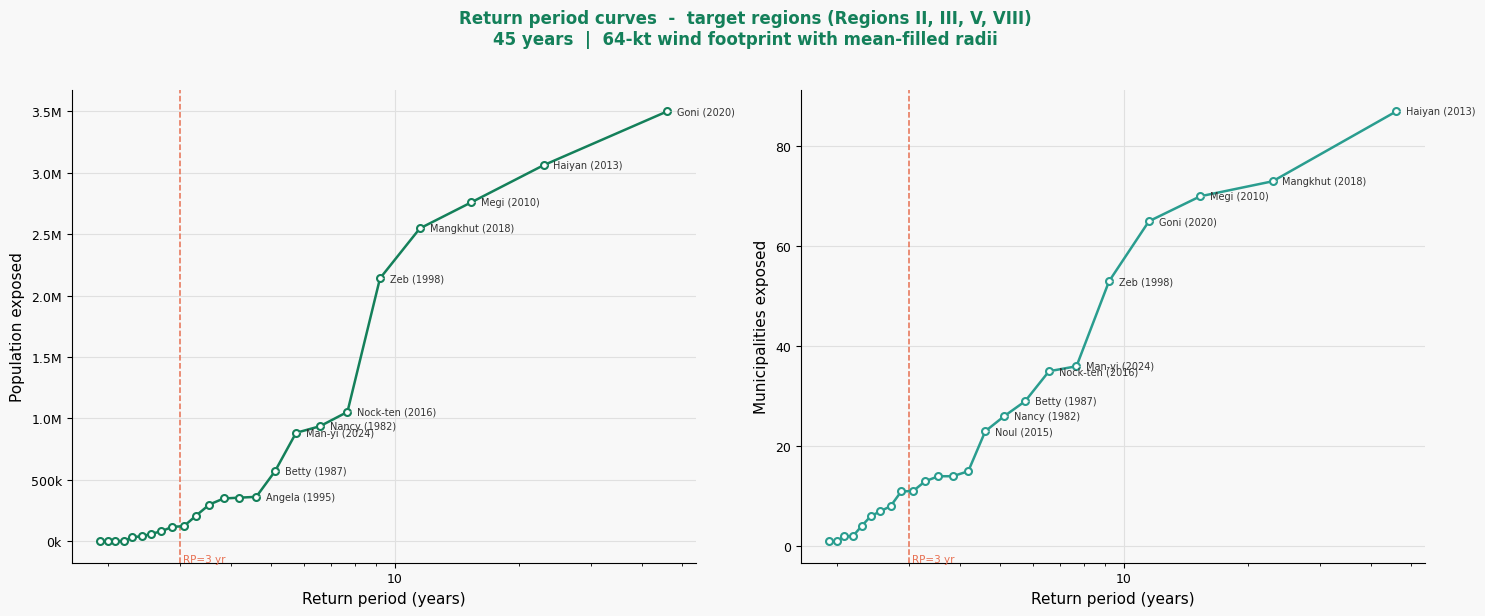

In [42]:
# ── Return period curves ──────────────────────────────────────────────────────
N_YEARS = END_YEAR - START_YEAR + 1
print(f"Record length: {N_YEARS} years  |  Storms ranked: {len(exposure)}")

def compute_rp(series, n_years):
    s = series.sort_values(ascending=False).reset_index(drop=True)
    s.index += 1
    rp = (n_years + 1) / s.index.values
    return s.values, rp

pop_vals, pop_rp = compute_rp(exposure["population_exposed"], N_YEARS)
muni_vals, muni_rp = compute_rp(exposure["n_munis"], N_YEARS)

# ── Labels: top 10 storms ────────────────────────────────────────────────────
def top_labels(df, col, n=10):
    top = df.nlargest(n, col)
    return list(zip(top[col].values, (top["name"] + " (" + top["year"].fillna("?") + ")").values))

pop_labels  = top_labels(exposure, "population_exposed")
muni_labels = top_labels(exposure, "n_munis")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor("#f8f8f8")

for ax, vals, rp_yrs, labels, ylabel, color in [
    (axes[0], pop_vals,  pop_rp,  pop_labels,  "Population exposed",       HEADER_COLOR),
    (axes[1], muni_vals, muni_rp, muni_labels, "Municipalities exposed",   "#2a9d8f"),
]:
    ax.set_facecolor("#f8f8f8")
    ax.plot(rp_yrs, vals, "o-", color=color, linewidth=1.8,
            markersize=5, markerfacecolor="white", markeredgewidth=1.5, zorder=3)

    for val, label in labels:
        idx  = np.argmin(np.abs(vals - val))
        rp_v = rp_yrs[idx]
        ax.annotate(
            label, xy=(rp_v, val),
            xytext=(7, 0), textcoords="offset points",
            fontsize=7, color="#333", va="center",
            arrowprops=dict(arrowstyle="-", color="#ccc", lw=0.5),
        )

    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_xlabel("Return period (years)", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    if ylabel == "Population exposed":
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
        ))
    ax.axvline(3, color="#e76f51", linewidth=1.1, linestyle="--", zorder=2)
    ax.text(3.05, ax.get_ylim()[0] * 1.05, "RP=3 yr",
            fontsize=7.5, color="#e76f51", va="bottom")
    ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
    ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=9)

fig.suptitle(
    f"Return period curves  -  target regions (Regions II, III, V, VIII)\n"
    f"{N_YEARS} years  |  64-kt wind footprint with mean-filled radii",
    fontsize=12, fontweight="bold", y=1.02, color=HEADER_COLOR,
)
plt.tight_layout()
plt.show()

In [43]:
# ── Population threshold sweep: RP at each threshold ─────────────────────────
# For each candidate population threshold, count how many seasons had
# at least one storm exceeding that threshold in the target regions.
# RP = N_years / n_activated_seasons

thresholds = [
    100_000, 250_000, 500_000, 750_000,
    1_000_000, 1_500_000, 2_000_000, 3_000_000, 5_000_000,
]

exposure_with_year = exposure.copy()
exposure_with_year["year_int"] = exposure_with_year["year"].dropna().astype(int)

rows = []
for thr in thresholds:
    above = exposure_with_year[exposure_with_year["population_exposed"] >= thr]
    n_seasons = above["year_int"].nunique()
    rp = N_YEARS / n_seasons if n_seasons > 0 else float("inf")
    rows.append({
        "threshold": thr,
        "n_seasons": n_seasons,
        "rp_yr": round(rp, 1),
        "storms": len(above),
    })

sweep_df = pd.DataFrame(rows)
print("Population threshold sweep:")
print(
    sweep_df.assign(
        threshold=lambda d: d["threshold"].apply(lambda v: f"{v/1e6:.2f}M" if v >= 1e6 else f"{v/1e3:.0f}k")
    ).to_string(index=False)
)

Population threshold sweep:
threshold  n_seasons  rp_yr  storms
     100k         14    3.2      16
     250k         13    3.5      13
     500k          9    5.0       9
     750k          8    5.6       8
    1.00M          6    7.5       6
    1.50M          5    9.0       5
    2.00M          5    9.0       5
    3.00M          2   22.5       2
    5.00M          0    inf       0


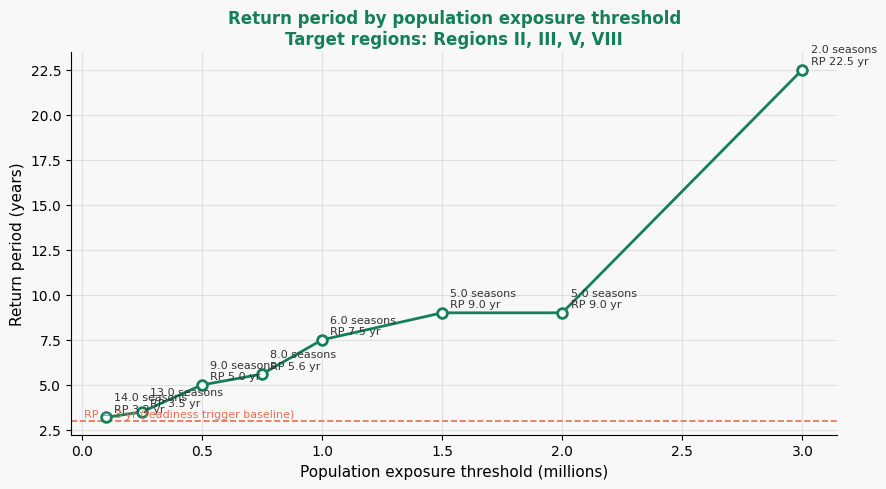

In [44]:
# ── Plot: RP vs population threshold ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

finite_mask = sweep_df["rp_yr"] < 100
ax.plot(
    sweep_df.loc[finite_mask, "threshold"] / 1e6,
    sweep_df.loc[finite_mask, "rp_yr"],
    "o-", color=HEADER_COLOR, linewidth=2,
    markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=3,
)
for _, row in sweep_df[finite_mask].iterrows():
    ax.annotate(
        f"{row['n_seasons']} seasons\nRP {row['rp_yr']} yr",
        xy=(row["threshold"] / 1e6, row["rp_yr"]),
        xytext=(6, 4), textcoords="offset points",
        fontsize=8, color="#333",
    )

ax.axhline(3.0, color="#e76f51", linewidth=1.2, linestyle="--")
ax.text(0.01, 3.1, "RP = 3 yr (readiness trigger baseline)",
        fontsize=8, color="#e76f51", va="bottom")

ax.set_xlabel("Population exposure threshold (millions)", fontsize=11)
ax.set_ylabel("Return period (years)", fontsize=11)
ax.set_title(
    "Return period by population exposure threshold\nTarget regions: Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", color=HEADER_COLOR,
)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [45]:
# ── Per-region breakdown ──────────────────────────────────────────────────────
# For each storm × region, clip the wind footprint to the region boundary and
# run zonal_stats  -  so only raster pixels inside the actual wind area are counted.
raster_crs = pop_target.rio.crs

region_rows = []
for _, reg_row in target_regions_gdf.iterrows():
    reg_geom_proj = (
        gpd.GeoSeries([reg_row.geometry], crs="EPSG:4326")
        .to_crs(CRS_METRIC)
        .iloc[0]
    )
    for _, fp_row in footprints.iterrows():
        clipped = fp_row.geometry.intersection(reg_geom_proj)
        if clipped.is_empty:
            continue
        clipped_gdf = gpd.GeoDataFrame(
            [{"geometry": clipped}], crs=CRS_METRIC
        ).to_crs(raster_crs)
        s = zonal_stats(
            clipped_gdf, pop_array,
            affine=pop_transform, stats=["sum"],
            nodata=nodata_val, all_touched=True,
        )[0]
        pop = int(round(s["sum"])) if s["sum"] else 0
        if pop > 0:
            region_rows.append({
                "storm_id": fp_row["storm_id"],
                "region": reg_row["adm1_name"],
                "population_exposed": pop,
            })

region_exposure = pd.DataFrame(region_rows).merge(
    storm_meta[["storm_id", "name", "year"]], on="storm_id"
)

# Pivot: storms × regions
region_pivot = region_exposure.pivot_table(
    index=["storm_id", "name", "year"],
    columns="region",
    values="population_exposed",
    aggfunc="sum",
    fill_value=0,
).reset_index().sort_values("year")

print("Top storms by region population exposure (raster-based):")
display(region_pivot.head(20))

Top storms by region population exposure (raster-based):


region,storm_id,name,year,Region II (Cagayan Valley),Region III (Central Luzon),Region V (Bicol Region),Region VIII (Eastern Visayas)
4,clara_wp_1981,Clara,1981,60043,0,0,0
16,nelson_wp_1982,Nelson,1982,0,0,0,1565
14,nancy_wp_1982,Nancy,1982,936323,0,0,0
0,agnes_wp_1984,Agnes,1984,0,0,0,348123
2,betty_wp_1987,Betty,1987,0,0,0,570387
6,elsie_wp_1989,Elsie,1989,896,0,0,0
1,angela_wp_1995,Angela,1995,0,0,361450,0
21,zeb_wp_1998,Zeb,1998,2140650,0,0,0
3,cimaron_wp_2006,Cimaron,2006,62058,55558,0,0
13,megi_wp_2010,Megi,2010,2738963,20681,0,0


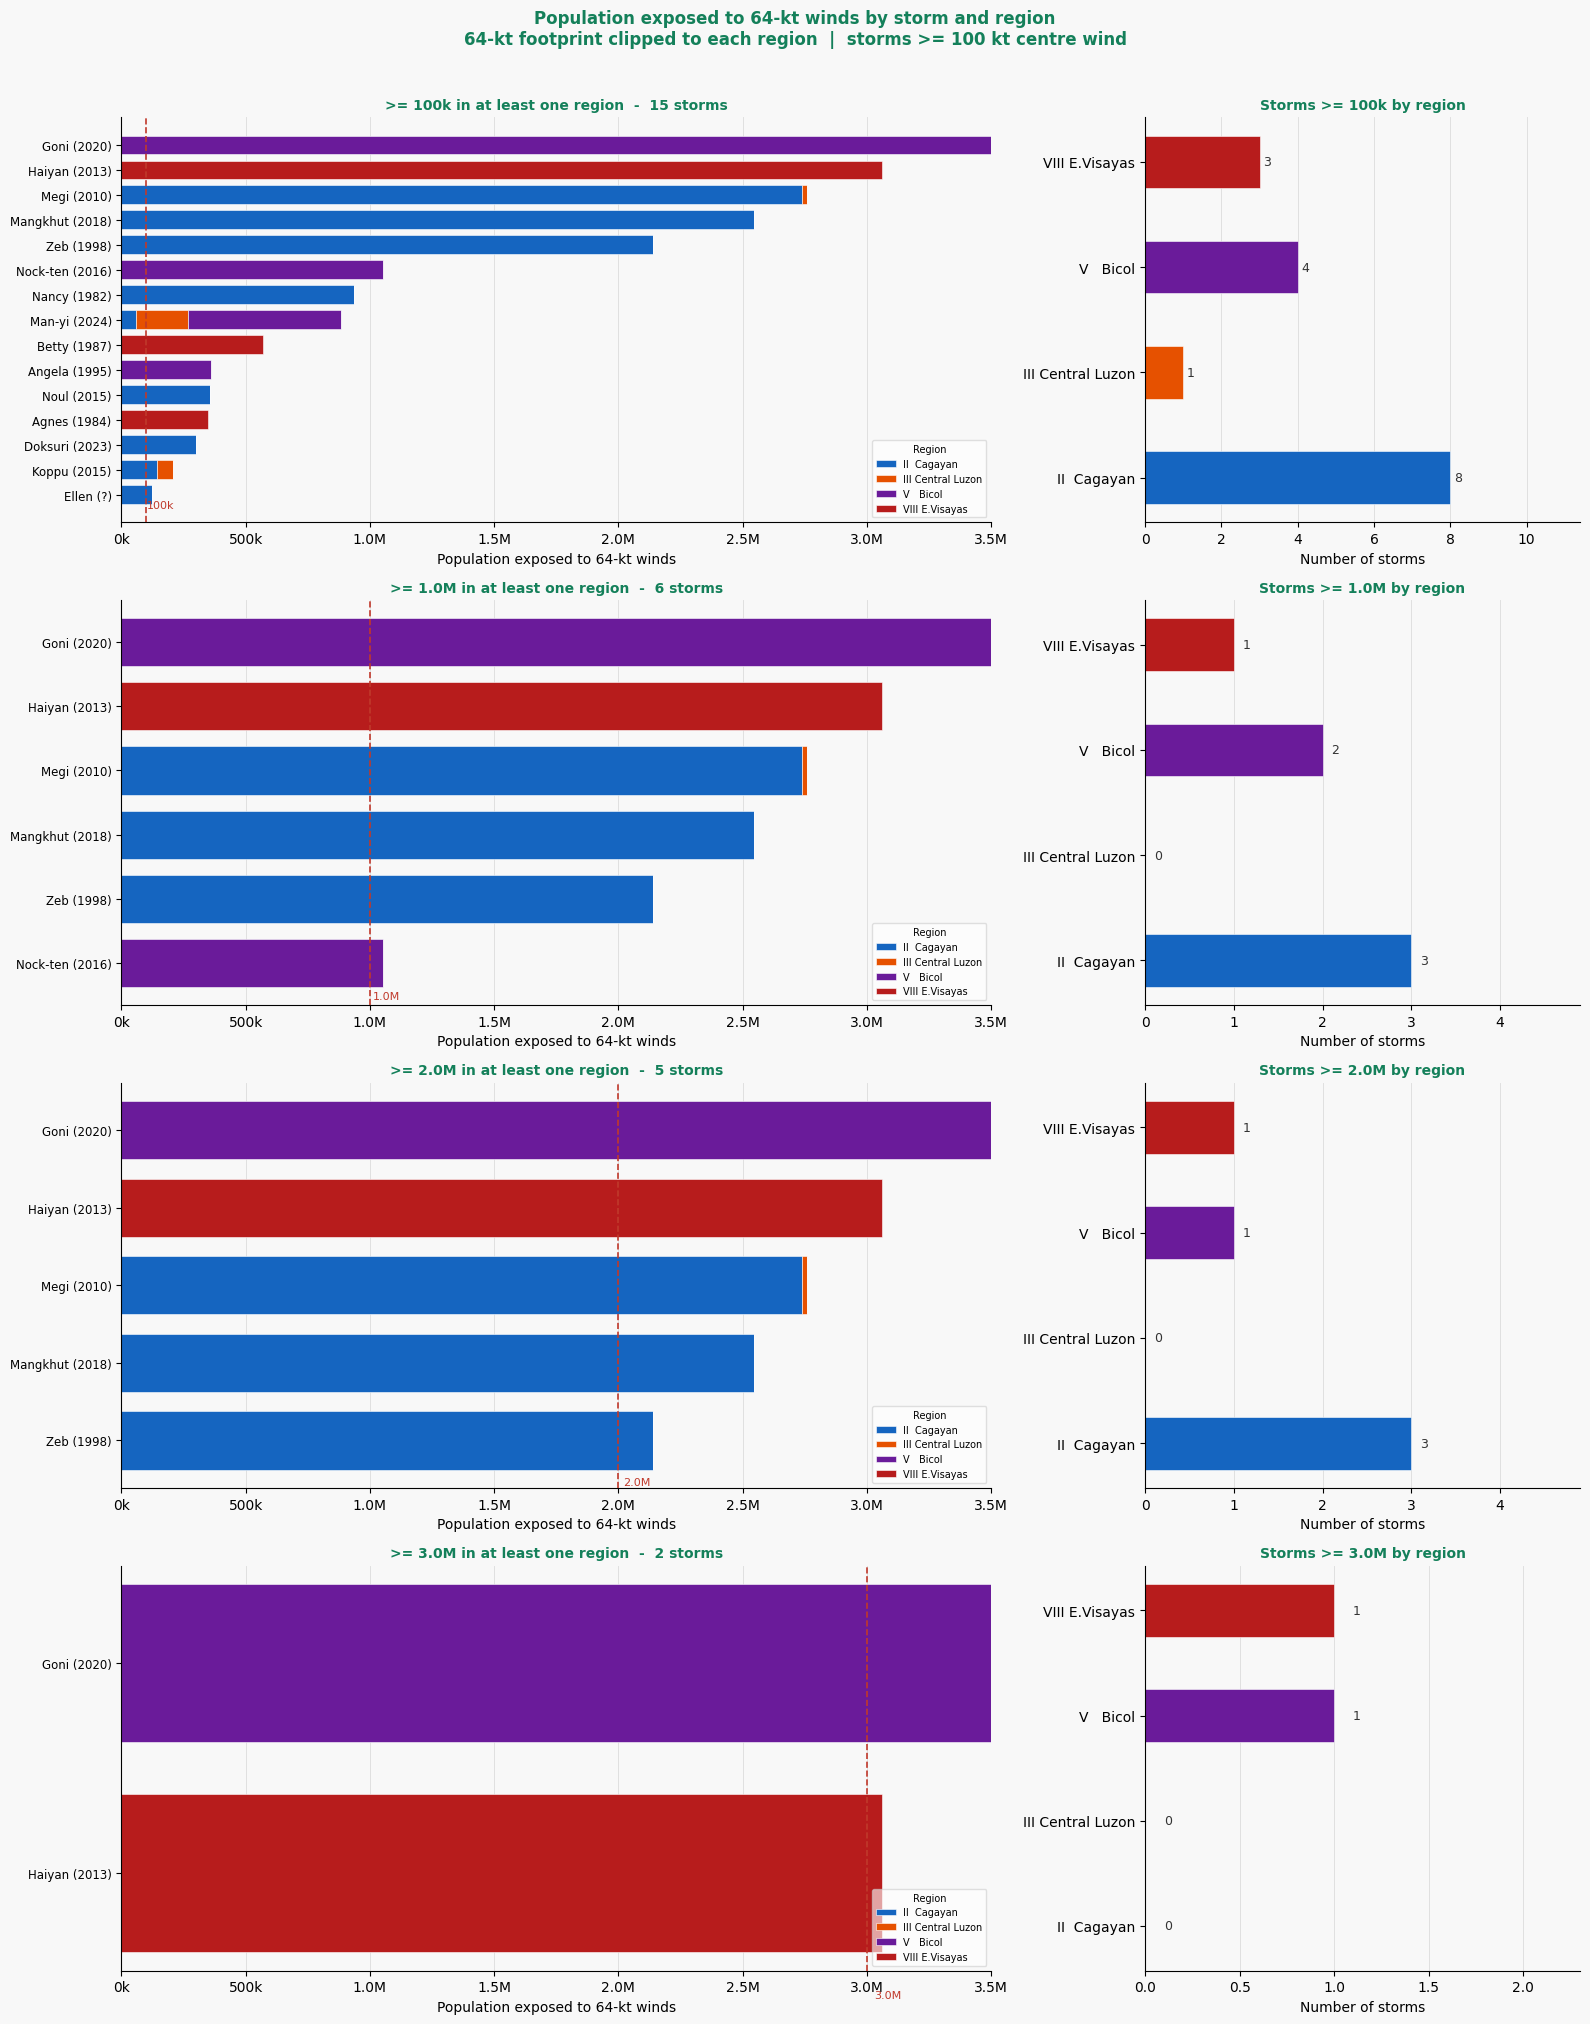

In [46]:
# ── Storms and population by region at each threshold ─────────────────────────
POP_THRESHOLDS = [100_000, 1_000_000, 2_000_000, 3_000_000]

short_names = {
    "Region II (Cagayan Valley)":    "II  Cagayan",
    "Region III (Central Luzon)":    "III Central Luzon",
    "Region V (Bicol Region)":       "V   Bicol",
    "Region VIII (Eastern Visayas)": "VIII E.Visayas",
}
region_cols  = list(short_names.keys())
colors_bar   = ["#1565C0", "#E65100", "#6A1B9A", "#B71C1C"]

region_exposure["label"] = (
    region_exposure["name"] + " (" + region_exposure["year"].fillna("?") + ")"
)

# Wide form: one row per storm, one column per region
reg_wide = region_exposure.pivot_table(
    index=["storm_id", "label"],
    columns="region",
    values="population_exposed",
    aggfunc="sum",
    fill_value=0,
).reset_index()

fig, axes = plt.subplots(
    len(POP_THRESHOLDS), 2,
    figsize=(16, len(POP_THRESHOLDS) * 5),
    gridspec_kw={"width_ratios": [2, 1]},
)
fig.patch.set_facecolor("#f8f8f8")

def _fmt_pop(v):
    return f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k"

for row, thr in enumerate(POP_THRESHOLDS):
    # Storms where at least one region exceeds the threshold
    exceeded_ids = region_exposure.loc[
        region_exposure["population_exposed"] >= thr, "storm_id"
    ].unique()

    sub = (
        reg_wide[reg_wide["storm_id"].isin(exceeded_ids)]
        .set_index("label")[region_cols]
    )
    # Sort by total across all regions
    sub = sub.loc[sub.sum(axis=1).sort_values(ascending=True).index]

    # ── Left: stacked bar chart ───────────────────────────────────────────────
    ax_s = axes[row, 0]
    ax_s.set_facecolor("#f8f8f8")

    lefts = np.zeros(len(sub))
    for col, color in zip(region_cols, colors_bar):
        vals = sub[col].values
        ax_s.barh(range(len(sub)), vals, left=lefts,
                  color=color, edgecolor="white", linewidth=0.4,
                  height=0.75, label=short_names[col])
        lefts += vals

    # Threshold line
    ax_s.axvline(thr, color="#c0392b", linewidth=1.2, linestyle="--", zorder=5)
    ax_s.text(thr * 1.01, -0.6, _fmt_pop(thr),
              color="#c0392b", fontsize=8, va="bottom")

    ax_s.set_yticks(range(len(sub)))
    ax_s.set_yticklabels(sub.index, fontsize=8.5)
    ax_s.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
    ))
    ax_s.set_xlabel("Population exposed to 64-kt winds", fontsize=10)
    ax_s.set_title(
        f">= {_fmt_pop(thr)} in at least one region  -  {len(sub)} storms",
        fontsize=10, fontweight="bold", color=HEADER_COLOR,
    )
    ax_s.legend(title="Region", fontsize=7, title_fontsize=7,
                loc="lower right", framealpha=0.6)
    ax_s.spines[["top", "right"]].set_visible(False)
    ax_s.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_s.set_axisbelow(True)

    # ── Right: count per region ───────────────────────────────────────────────
    ax_r = axes[row, 1]
    ax_r.set_facecolor("#f8f8f8")

    region_counts = (
        region_exposure[region_exposure["population_exposed"] >= thr]
        .groupby("region")["storm_id"].nunique()
        .reindex(region_cols, fill_value=0)
    )
    bars = ax_r.barh(
        [short_names[r] for r in region_cols],
        region_counts.values,
        color=colors_bar, edgecolor="white", linewidth=0.4, height=0.5,
    )
    for bar, val in zip(bars, region_counts.values):
        ax_r.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                  str(val), va="center", ha="left", fontsize=9, color="#333")

    ax_r.set_xlabel("Number of storms", fontsize=10)
    ax_r.set_title(
        f"Storms >= {_fmt_pop(thr)} by region",
        fontsize=10, fontweight="bold", color=HEADER_COLOR,
    )
    ax_r.set_xlim(0, region_counts.max() * 1.3 + 1)
    ax_r.spines[["top", "right"]].set_visible(False)
    ax_r.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_r.set_axisbelow(True)

plt.suptitle(
    f"Population exposed to 64-kt winds by storm and region\n"
    f"64-kt footprint clipped to each region  |  storms >= {KT_THRESHOLD:.0f} kt centre wind",
    fontsize=12, fontweight="bold", color=HEADER_COLOR, y=1.01,
)
plt.tight_layout()
plt.show()

## Fraction-of-Region Exposure  -  the 50% test

The threshold sweep above is in **absolute** people, which lets a large region
dominate: 1M exposed is a quarter of Cagayan Valley but under a tenth of Central
Luzon. This section re-runs the sweep in **relative** terms and asks:

> which storms put **>= 50% of a region's own population** inside the 64-kt footprint?

**Denominator.** Each region's total is the raster sum over the **region
polygon itself**, and the four together come to **29.3M**. Cell 6 now uses the
same basis. (It previously summed `admin3_target`, built with
`.intersects(target_union)`, which also admitted NCR, CAR, Region I and
Region IV-A municipalities that merely touch the boundary - NCR alone adding
5.1M - and reported 42.3M. Fixed 2026-08-25.)


In [47]:
# ── Region denominators: raster sum over each region polygon ──────────────────
# One polygon per region  -  avoids the admin-3 `all_touched` boundary
# double-count and excludes municipalities outside the target regions.
reg_poly = (
    target_regions_gdf[["adm1_name", "geometry"]]
    .to_crs(CRS_METRIC)
    .reset_index(drop=True)
)


def _zonal_sum(gdf_metric):
    """Population raster sum over geometries supplied in CRS_METRIC."""
    st = zonal_stats(
        gdf_metric.to_crs(raster_crs), pop_array, affine=pop_transform,
        stats=["sum"], nodata=nodata_val, all_touched=True,
    )
    return [int(round(s["sum"])) if s["sum"] else 0 for s in st]


reg_poly["pop_region_total"] = _zonal_sum(reg_poly)
region_totals = reg_poly.set_index("adm1_name")["pop_region_total"]

print("Population by target region (raster sum over region polygon):")
for _name, _pop in region_totals.items():
    print(f"  {_name:<32} {_pop:>12,}")
print(f"  {'TOTAL (4 target regions)':<32} {region_totals.sum():>12,}")
assert total_pop == region_totals.sum(), (
    f"cell-6 total_pop {total_pop:,} != region-polygon sum {region_totals.sum():,}"
)


Population by target region (raster sum over region polygon):
  Region II (Cagayan Valley)          3,989,175
  Region III (Central Luzon)         13,853,805
  Region V (Bicol Region)             6,543,178
  Region VIII (Eastern Visayas)       4,889,698
  TOTAL (4 target regions)           29,275,856


In [48]:
# ── Exposure as a share of each region's population ───────────────────────────
frac_rows = []
for _, reg in reg_poly.iterrows():
    for _, fp in footprints.iterrows():
        clipped = fp.geometry.intersection(reg.geometry)
        if clipped.is_empty:
            continue
        pop = _zonal_sum(gpd.GeoDataFrame([{"geometry": clipped}], crs=CRS_METRIC))[0]
        if pop <= 0:
            continue
        frac_rows.append({
            "storm_id": fp["storm_id"],
            "region": reg["adm1_name"],
            "pop_exposed": pop,
            "n_munis_region": int(admin3_target_proj.intersects(clipped).sum()),
            "pop_region_total": reg["pop_region_total"],
        })

frac_exp = (
    pd.DataFrame(frac_rows)
    .merge(storm_meta[["storm_id", "name", "year", "max_wind_kmh"]], on="storm_id")
)
frac_exp["frac_exposed"] = frac_exp["pop_exposed"] / frac_exp["pop_region_total"]
frac_exp = frac_exp.sort_values("frac_exposed", ascending=False).reset_index(drop=True)

FRAC_TARGET = 0.50
hits = frac_exp[frac_exp["frac_exposed"] >= FRAC_TARGET]

print(f"Storms exposing >= {FRAC_TARGET:.0%} of a region's population to 64-kt winds\n")
display(
    hits[["name", "year", "region", "max_wind_kmh", "n_munis_region",
          "pop_exposed", "pop_region_total", "frac_exposed"]]
    .assign(
        pop_exposed=lambda d: d["pop_exposed"].map("{:,}".format),
        pop_region_total=lambda d: d["pop_region_total"].map("{:,}".format),
        frac_exposed=lambda d: (d["frac_exposed"] * 100).round(1).astype(str) + "%",
    )
    .reset_index(drop=True)
)

_seasons = hits["year"].dropna().nunique()
print(f"{len(hits)} storm-region activations in {_seasons} seasons "
      f"-> RP {N_YEARS / _seasons:.1f} yr")

# Sensitivity: how far can the threshold move without changing the storm set?
_ranked = frac_exp["frac_exposed"].values
print(f"5th-highest fraction {_ranked[4]:.1%}  |  6th-highest {_ranked[5]:.1%}"
      f"  -> any threshold in ({_ranked[5]:.0%}, {_ranked[4]:.0%}] yields the same storms")


Storms exposing >= 50% of a region's population to 64-kt winds



,name,year,region,max_wind_kmh,n_munis_region,pop_exposed,pop_region_total,frac_exposed
0,Megi,2010,Region II (Cagayan Valley),231.5,69,"2,738,963","3,989,175",68.7%
1,Mangkhut,2018,Region II (Cagayan Valley),203.7,73,"2,547,622","3,989,175",63.9%
2,Haiyan,2013,Region VIII (Eastern Visayas),231.5,87,"3,062,238","4,889,698",62.6%
3,Zeb,1998,Region II (Cagayan Valley),203.7,53,"2,140,650","3,989,175",53.7%
4,Goni,2020,Region V (Bicol Region),222.2,65,"3,501,347","6,543,178",53.5%


5 storm-region activations in 5 seasons -> RP 9.0 yr
5th-highest fraction 53.5%  |  6th-highest 23.5%  -> any threshold in (23%, 54%] yields the same storms


In [49]:
# ── Sweep: RP by fraction-of-region threshold ────────────────────────────────
frac_thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70]

frac_sweep_rows = []
for f in frac_thresholds:
    above = frac_exp[frac_exp["frac_exposed"] >= f]
    n_seasons = above["year"].dropna().nunique()
    frac_sweep_rows.append({
        "frac": f,
        "storms": above["storm_id"].nunique(),
        "seasons": n_seasons,
        "rp_yr": round(N_YEARS / n_seasons, 1) if n_seasons else float("inf"),
        "regions": above["region"].nunique(),
    })

frac_sweep = pd.DataFrame(frac_sweep_rows)
print("Fraction-of-region threshold sweep:")
print(
    frac_sweep.assign(frac=lambda d: (d["frac"] * 100).astype(int).astype(str) + "%")
    .to_string(index=False)
)

# Highest attainable fraction per region  -  is 50% even reachable?
print("\nBest storm per region:")
print(
    frac_exp.sort_values("frac_exposed", ascending=False)
    .groupby("region").head(1)[["region", "name", "year", "frac_exposed"]]
    .assign(frac_exposed=lambda d: (d["frac_exposed"] * 100).round(1).astype(str) + "%")
    .to_string(index=False)
)


Fraction-of-region threshold sweep:
frac  storms  seasons  rp_yr  regions
  5%      13       13    3.5        3
 10%       8        8    5.6        3
 15%       7        7    6.4        3
 20%       6        6    7.5        3
 25%       5        5    9.0        3
 30%       5        5    9.0        3
 40%       5        5    9.0        3
 50%       5        5    9.0        3
 60%       3        3   15.0        2
 70%       0        0    inf        0

Best storm per region:
                       region   name year frac_exposed
   Region II (Cagayan Valley)   Megi 2010        68.7%
Region VIII (Eastern Visayas) Haiyan 2013        62.6%
      Region V (Bicol Region)   Goni 2020        53.5%
   Region III (Central Luzon) Man-yi 2024         1.5%


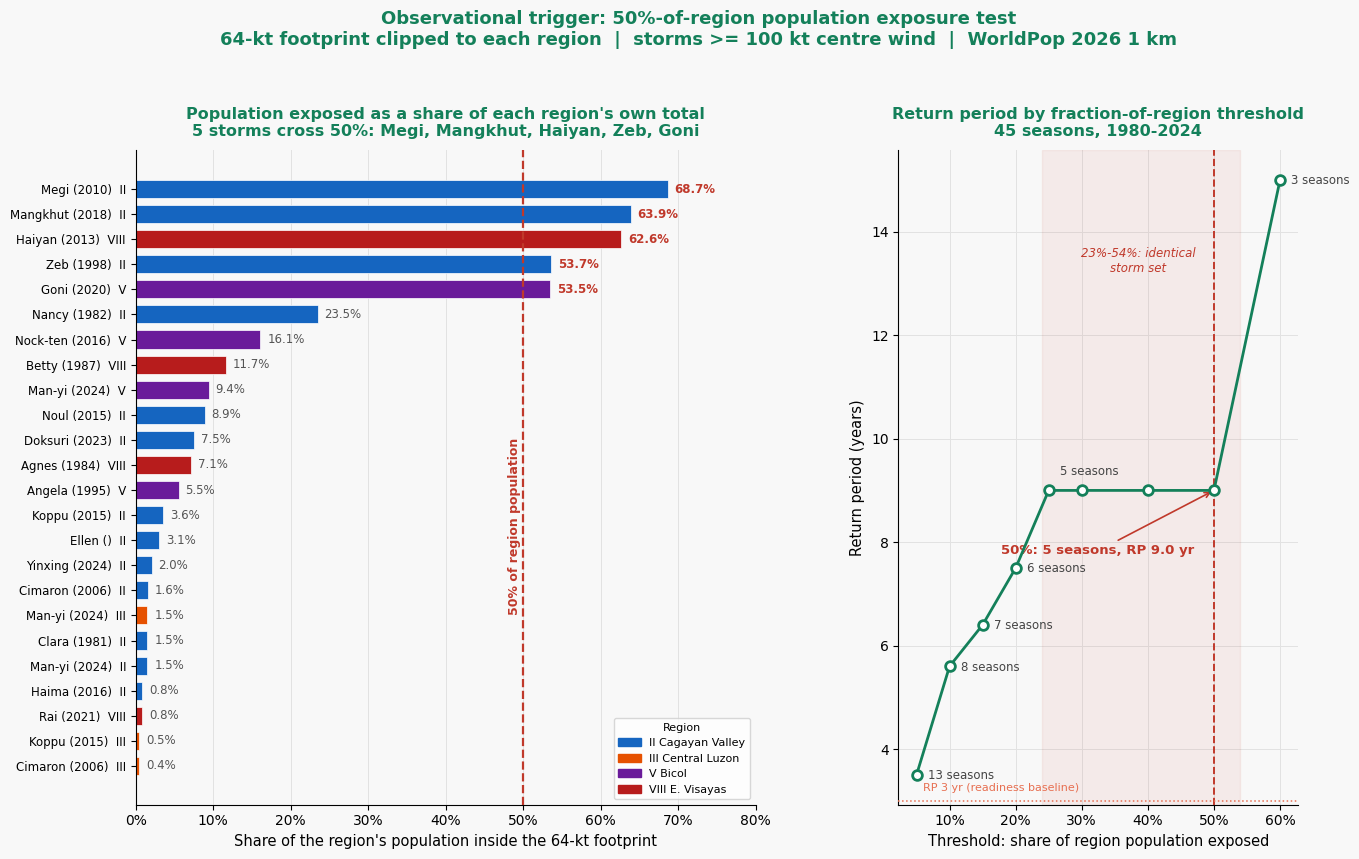

In [50]:
# ── Chart: share of region population exposed, and RP by fraction threshold ───
REG_ORDER = [
    "Region II (Cagayan Valley)",
    "Region III (Central Luzon)",
    "Region V (Bicol Region)",
    "Region VIII (Eastern Visayas)",
]
REG_SHORT = {
    "Region II (Cagayan Valley)":    "II Cagayan Valley",
    "Region III (Central Luzon)":    "III Central Luzon",
    "Region V (Bicol Region)":       "V Bicol",
    "Region VIII (Eastern Visayas)": "VIII E. Visayas",
}
REG_COLORS = dict(zip(REG_ORDER, ["#1565C0", "#E65100", "#6A1B9A", "#B71C1C"]))

fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.28)
fig.patch.set_facecolor("#f8f8f8")

# ── Left: every storm x region pair as a share of that region's population ────
ax = fig.add_subplot(gs[0, 0])
ax.set_facecolor("#f8f8f8")
plot_df = frac_exp[frac_exp["frac_exposed"] >= 0.002].sort_values("frac_exposed")
bar_labels = [
    f"{r['name']} ({'' if pd.isna(r['year']) else r['year']})  "
    f"{REG_SHORT[r['region']].split()[0]}"
    for _, r in plot_df.iterrows()
]
bars = ax.barh(
    range(len(plot_df)), plot_df["frac_exposed"] * 100,
    color=[REG_COLORS[r] for r in plot_df["region"]],
    edgecolor="white", linewidth=0.5, height=0.72,
)
for bar, v in zip(bars, plot_df["frac_exposed"] * 100):
    ax.text(bar.get_width() + 0.9, bar.get_y() + bar.get_height() / 2,
            f"{v:.1f}%", va="center", ha="left", fontsize=8.5,
            color="#c0392b" if v >= FRAC_TARGET * 100 else "#555",
            fontweight="bold" if v >= FRAC_TARGET * 100 else "normal")

ax.axvline(FRAC_TARGET * 100, color="#c0392b", linewidth=1.6, linestyle="--", zorder=5)
ax.text(FRAC_TARGET * 100 - 1.1, 6.0, f"{FRAC_TARGET:.0%} of region population",
        color="#c0392b", fontsize=9, va="bottom", ha="center",
        rotation=90, fontweight="bold",
        bbox=dict(boxstyle="square,pad=0.15", fc="#f8f8f8", ec="none"))
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(bar_labels, fontsize=8.5)
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_xlabel("Share of the region's population inside the 64-kt footprint",
              fontsize=10.5)
ax.set_title(
    "Population exposed as a share of each region's own total\n"
    + f"{len(hits)} storms cross {FRAC_TARGET:.0%}: "
    + ", ".join(hits["name"].tolist()),
    fontsize=11.5, fontweight="bold", color=HEADER_COLOR, pad=10,
)
ax.legend(
    [plt.Rectangle((0, 0), 1, 1, color=REG_COLORS[r]) for r in REG_ORDER],
    [REG_SHORT[r] for r in REG_ORDER],
    title="Region", fontsize=8, title_fontsize=8, loc="lower right", framealpha=0.75,
)
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.grid(True, color="#e2e2e2", linewidth=0.7)
ax.set_axisbelow(True)

# ── Right: RP by fraction threshold ──────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_facecolor("#f8f8f8")
fin = frac_sweep[np.isfinite(frac_sweep["rp_yr"])]
ax2.plot(fin["frac"] * 100, fin["rp_yr"], "o-", color=HEADER_COLOR, linewidth=2,
         markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=4)

_seen = set()
for _, r in fin.iterrows():
    n = int(r["seasons"])
    if n in _seen:                      # label each plateau once, at its left end
        continue
    _seen.add(n)
    ax2.annotate(f"{n} seasons", xy=(r["frac"] * 100, r["rp_yr"]),
                 xytext=(8, 11 if n == _seasons else -3),
                 textcoords="offset points", fontsize=8.5, color="#444")

_rp_at_target = float(frac_sweep.loc[frac_sweep["frac"] == FRAC_TARGET, "rp_yr"].iloc[0])
ax2.axvline(FRAC_TARGET * 100, color="#c0392b", linewidth=1.4, linestyle="--", zorder=3)
ax2.axhline(3.0, color="#e76f51", linewidth=1.1, linestyle=":", zorder=3)
ax2.text(6, 3.2, "RP 3 yr (readiness baseline)", fontsize=8, color="#e76f51")
ax2.annotate(
    f"{FRAC_TARGET:.0%}: {int(_seasons)} seasons, RP {_rp_at_target} yr",
    xy=(FRAC_TARGET * 100, _rp_at_target), xytext=(-14, -46),
    textcoords="offset points", fontsize=9.5, fontweight="bold",
    color="#c0392b", ha="right",
    arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.2),
)
# Shade the band over which the qualifying storm set does not change
ax2.axvspan(_ranked[5] * 100 + 0.5, _ranked[4] * 100 + 0.5,
            color="#c0392b", alpha=0.07, zorder=1)
ax2.text((_ranked[5] + _ranked[4]) / 2 * 100, ax2.get_ylim()[1] * 0.88,
         f"{_ranked[5]:.0%}-{_ranked[4]:.0%}: identical\nstorm set",
         fontsize=8.5, color="#c0392b", ha="center", va="top", style="italic")
ax2.set_xlabel("Threshold: share of region population exposed", fontsize=10.5)
ax2.set_ylabel("Return period (years)", fontsize=10.5)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax2.set_title(f"Return period by fraction-of-region threshold\n"
              f"{N_YEARS} seasons, {START_YEAR}-{END_YEAR}",
              fontsize=11.5, fontweight="bold", color=HEADER_COLOR, pad=10)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(True, color="#e2e2e2", linewidth=0.7)
ax2.set_axisbelow(True)

fig.suptitle(
    f"Observational trigger: {FRAC_TARGET:.0%}-of-region population exposure test\n"
    f"64-kt footprint clipped to each region  |  storms >= {KT_THRESHOLD:.0f} kt "
    f"centre wind  |  WorldPop 2026 1 km",
    fontsize=13, fontweight="bold", color=HEADER_COLOR, y=1.045,
)
plt.show()


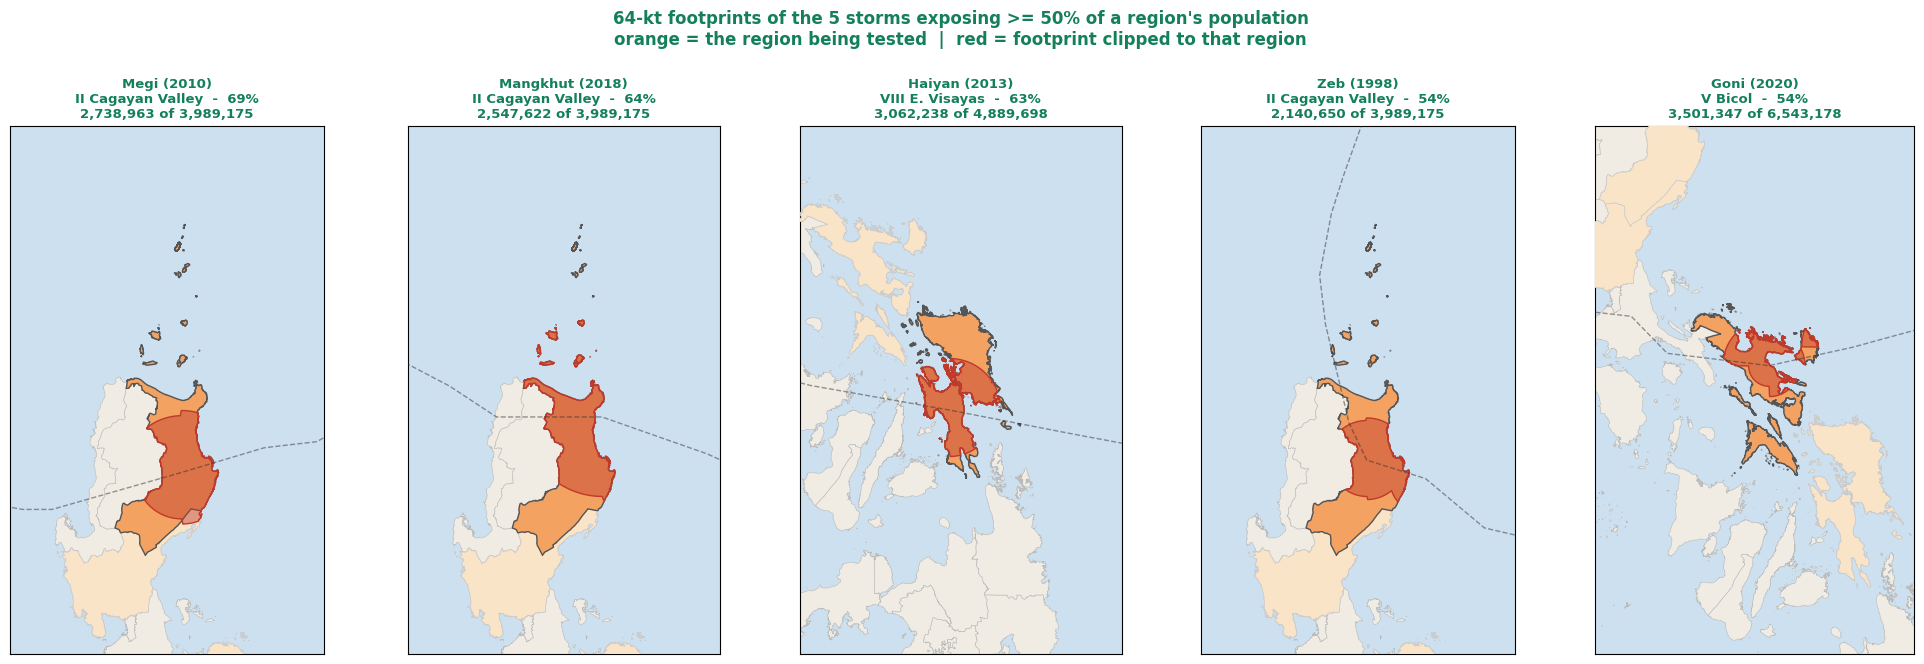

In [51]:
# ── Map: the storms that cross the 50% mark ──────────────────────────────────
fig, axes = plt.subplots(1, len(hits), figsize=(4.0 * len(hits), 6.4))
axes = np.atleast_1d(axes)

# Common window size for every panel, so the maps share a scale and the
# subplot titles line up. Each panel is centred on its own region.
_spans = [
    target_regions_gdf[target_regions_gdf["adm1_name"] == r].total_bounds
    for r in hits["region"]
]
_half_w = max((b[2] - b[0]) for b in _spans) / 2 + 1.6
_half_h = max((b[3] - b[1]) for b in _spans) / 2 + 1.6

for ax_m, (_, hit) in zip(axes, hits.iterrows()):
    ax_m.set_facecolor("#cde0f0")
    reg_geom = target_regions_gdf[target_regions_gdf["adm1_name"] == hit["region"]]
    fp = footprints[footprints["storm_id"] == hit["storm_id"]].to_crs("EPSG:4326")
    trk = tracks_hist[tracks_hist["storm_id"] == hit["storm_id"]].sort_values("valid_time")

    phl_admin_1.plot(ax=ax_m, color="#f0ece3", edgecolor="#bbb", linewidth=0.4, zorder=2)
    target_regions_gdf.plot(ax=ax_m, color="#f9e4c8", edgecolor="#ccc",
                            linewidth=0.5, zorder=3)
    reg_geom.plot(ax=ax_m, color="#f4a261", edgecolor="#555", linewidth=1.0, zorder=4)
    if not fp.empty:
        fp.plot(ax=ax_m, color="#c0392b", alpha=0.45, zorder=5)
        fp.boundary.plot(ax=ax_m, color="#c0392b", linewidth=1.0, zorder=6)
    ax_m.plot(list(trk.geometry.x), list(trk.geometry.y), color="#333",
              linewidth=1.0, linestyle="--", alpha=0.5, zorder=7)

    _minx, _miny, _maxx, _maxy = reg_geom.total_bounds
    _cx, _cy = (_minx + _maxx) / 2, (_miny + _maxy) / 2
    ax_m.set_xlim(_cx - _half_w, _cx + _half_w)
    ax_m.set_ylim(_cy - _half_h, _cy + _half_h)
    ax_m.set_xticks([])
    ax_m.set_yticks([])
    ax_m.set_title(
        f"{hit['name']} ({hit['year']})\n"
        f"{REG_SHORT[hit['region']]}  -  {hit['frac_exposed']:.0%}\n"
        f"{hit['pop_exposed']:,} of {hit['pop_region_total']:,}",
        fontsize=9.5, fontweight="bold", color=HEADER_COLOR,
    )

fig.suptitle(
    f"64-kt footprints of the {len(hits)} storms exposing >= {FRAC_TARGET:.0%} "
    f"of a region's population\n"
    "orange = the region being tested  |  red = footprint clipped to that region",
    fontsize=12, fontweight="bold", color=HEADER_COLOR, y=1.03,
)
plt.tight_layout()
plt.show()


In [52]:
# ── Save the fraction-of-region exposure table ────────────────────────────────
_save_frac = frac_exp[[
    "storm_id", "name", "year", "region", "max_wind_kmh", "n_munis_region",
    "pop_exposed", "pop_region_total", "frac_exposed",
]].sort_values(["region", "frac_exposed"], ascending=[True, False]).reset_index(drop=True)

_blob_frac = "pa-aa-phl-storms/processed/trigger_activations/obs_wind_region_fraction.parquet"
stratus.upload_parquet_to_blob(_save_frac, _blob_frac, stage=STAGE, container_name=CONTAINER)
print(f"Saved {len(_save_frac)} storm-region rows -> {_blob_frac}")


Saved 28 storm-region rows -> pa-aa-phl-storms/processed/trigger_activations/obs_wind_region_fraction.parquet


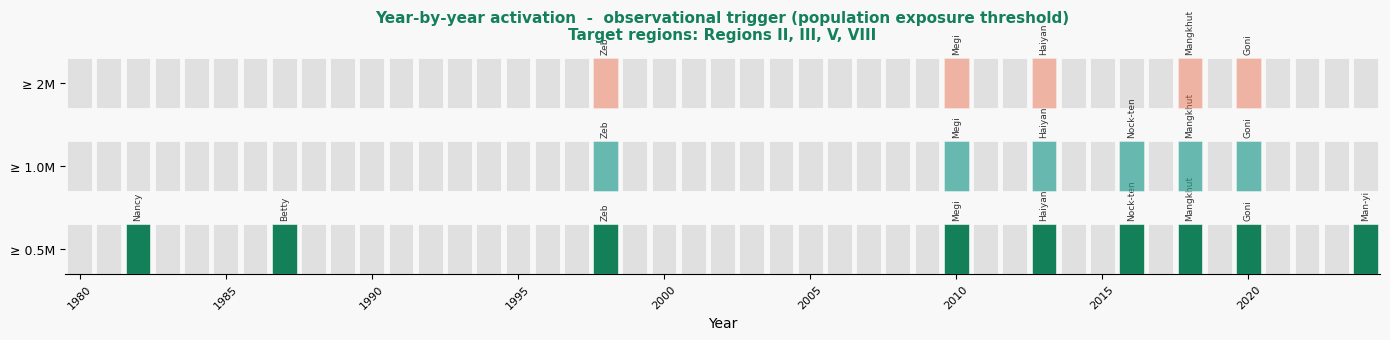

  ≥ 0.5M:  9 seasons  RP ≈ 5.0 yr  [1982, 1987, 1998, 2010, 2013, 2016, 2018, 2020, 2024]
  ≥ 1.0M:  6 seasons  RP ≈ 7.5 yr  [1998, 2010, 2013, 2016, 2018, 2020]
    ≥ 2M:  5 seasons  RP ≈ 9.0 yr  [1998, 2010, 2013, 2018, 2020]


In [53]:
# ── Year-by-year activation timeline ─────────────────────────────────────────
# Using 3 illustrative population thresholds
THRESHOLD_LOW  =   500_000
THRESHOLD_MID  = 1_000_000
THRESHOLD_HIGH = 2_000_000

all_years = list(range(START_YEAR, END_YEAR + 1))

def activated_years(threshold):
    above = exposure_with_year[exposure_with_year["population_exposed"] >= threshold]
    return set(above["year_int"].dropna().astype(int))

act_low  = activated_years(THRESHOLD_LOW)
act_mid  = activated_years(THRESHOLD_MID)
act_high = activated_years(THRESHOLD_HIGH)

fig, ax = plt.subplots(figsize=(14, 3.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

labels = [
    (f"≥ {THRESHOLD_LOW/1e6:.1f}M",  act_low,  "#14805a", 1.0),
    (f"≥ {THRESHOLD_MID/1e6:.1f}M",  act_mid,  "#2a9d8f", 0.7),
    (f"≥ {THRESHOLD_HIGH/1e6:.0f}M", act_high, "#e76f51", 0.5),
]

y_pos = {lbl: i for i, (lbl, _, _, _) in enumerate(labels)}

for lbl, act_set, color, alpha in labels:
    y = y_pos[lbl]
    for yr in all_years:
        if yr in act_set:
            # Find storm names
            names = exposure_with_year[
                (exposure_with_year["year_int"] == yr) &
                (exposure_with_year["population_exposed"] >= {
                    f"≥ {THRESHOLD_LOW/1e6:.1f}M":  THRESHOLD_LOW,
                    f"≥ {THRESHOLD_MID/1e6:.1f}M":  THRESHOLD_MID,
                    f"≥ {THRESHOLD_HIGH/1e6:.0f}M": THRESHOLD_HIGH,
                }[lbl])
            ]["name"].tolist()
            ax.bar(yr, 0.6, bottom=y - 0.3, color=color, alpha=alpha,
                   width=0.85, zorder=3, edgecolor="white", linewidth=0.4)
            ax.text(yr, y + 0.35, ", ".join(names[:2]),
                    ha="center", va="bottom", fontsize=6.5, color="#333",
                    rotation=90)
        else:
            ax.bar(yr, 0.6, bottom=y - 0.3, color="#e0e0e0", width=0.85,
                   zorder=2, edgecolor="white", linewidth=0.4)

ax.set_yticks([y_pos[lbl] for lbl, *_ in labels])
ax.set_yticklabels([lbl for lbl, *_ in labels], fontsize=9)
ax.set_xlim(START_YEAR - 0.5, END_YEAR + 0.5)
ax.set_xlabel("Year", fontsize=10)
ax.set_title(
    "Year-by-year activation  -  observational trigger (population exposure threshold)\n"
    "Target regions: Regions II, III, V, VIII",
    fontsize=11, fontweight="bold", color=HEADER_COLOR,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="x", labelsize=8, rotation=45)
plt.tight_layout()
plt.show()

for lbl, act_set, _, _ in labels:
    rp = N_YEARS / len(act_set) if act_set else float("inf")
    print(f"{lbl:>8}: {len(act_set):>2} seasons  RP ≈ {rp:.1f} yr  {sorted(act_set)}")

Worst storm: Goni (2020)  -  3,501,347 people  65 munis


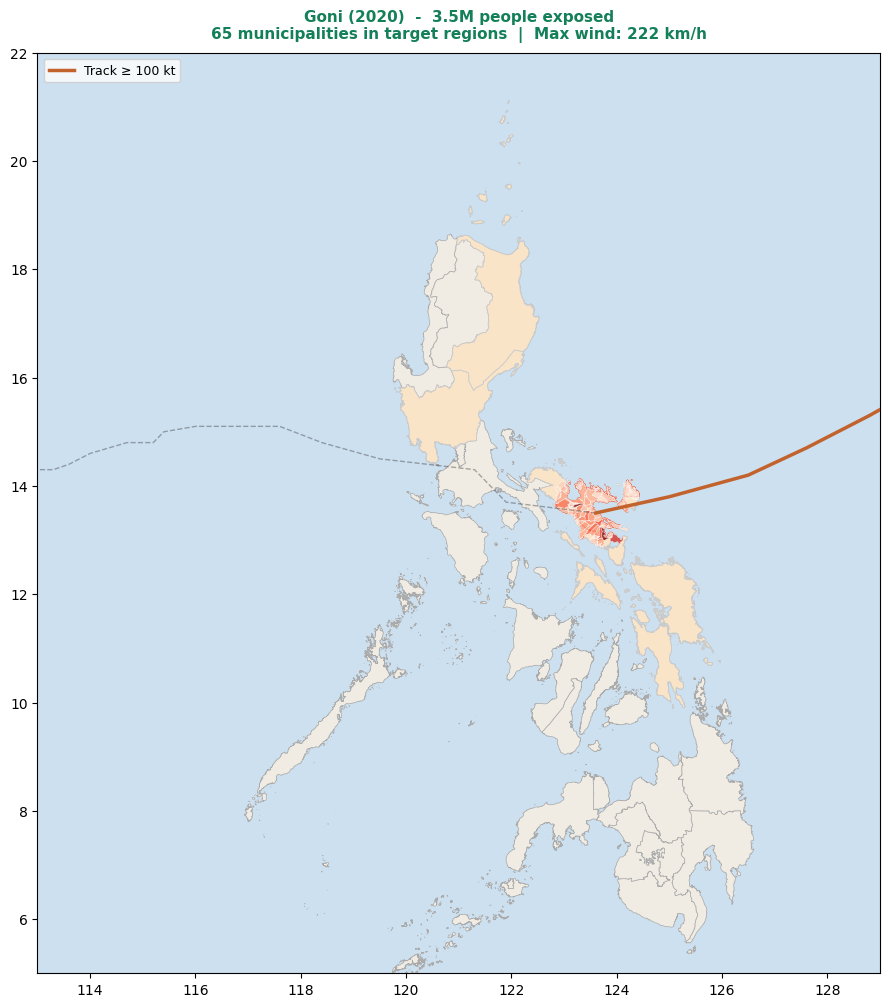

In [54]:
# ── Map: worst-case storm in target regions ───────────────────────────────────
worst_storm = exposure.iloc[0]
worst_id    = worst_storm["storm_id"]
print(f"Worst storm: {worst_storm['name']} ({worst_storm['year']})  -  "
      f"{worst_storm['population_exposed']:,.0f} people  {worst_storm['n_munis']} munis")

worst_track   = tracks_hist[tracks_hist["storm_id"] == worst_id].sort_values("valid_time")
worst_intense = worst_track[worst_track["wind_speed"] >= KT_THRESHOLD]
worst_line    = LineString(list(zip(worst_track.geometry.x, worst_track.geometry.y)))

worst_muni_idx = joined[joined["storm_id"] == worst_id].index.unique()
worst_munis    = admin3_target_pop.loc[worst_muni_idx]
worst_footprint = footprints[footprints["storm_id"] == worst_id].to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(9, 11))
ax.set_facecolor("#cde0f0")

# Admin-1 background
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5, zorder=2)
target_regions_gdf.plot(ax=ax, color="#f9e4c8", edgecolor="#ccc", linewidth=0.6, zorder=3)

# Wind footprint
if not worst_footprint.empty:
    worst_footprint.plot(ax=ax, color="#e76f51", alpha=0.25, zorder=4)
    worst_footprint.boundary.plot(ax=ax, color="#e76f51", linewidth=1.0, zorder=5)

# Exposed municipalities
worst_munis.plot(ax=ax, column="population", cmap="Reds", alpha=0.7,
                 edgecolor="white", linewidth=0.3, zorder=6)

# Track
xs, ys = worst_line.xy
ax.plot(xs, ys, color="#333", linewidth=1.0, alpha=0.4, linestyle="--", zorder=7)
if len(worst_intense) >= 2:
    ax.plot(
        list(worst_intense.geometry.x), list(worst_intense.geometry.y),
        color="#c2622d", linewidth=2.5, zorder=8,
        label=f"Track ≥ {KT_THRESHOLD:.0f} kt",
    )

ax.set_xlim(113, 129); ax.set_ylim(5, 22)
ax.legend(fontsize=9, loc="upper left")
ax.set_title(
    f"{worst_storm['name']} ({worst_storm['year']})  -  "
    f"{worst_storm['population_exposed']/1e6:.1f}M people exposed\n"
    f"{worst_storm['n_munis']} municipalities in target regions  |  "
    f"Max wind: {worst_storm['max_wind_kmh']:.0f} km/h",
    fontsize=11, fontweight="bold", color=HEADER_COLOR, pad=10,
)
plt.tight_layout()
plt.show()

In [55]:
# ── Summary table ─────────────────────────────────────────────────────────────
print("=" * 70)
print("OBSERVATIONAL TRIGGER  -  SUMMARY")
print(f"Record: {START_YEAR}-{END_YEAR} ({N_YEARS} years)")
print(f"Regions: {', '.join(target_regions_gdf['adm1_name'].tolist())}")
print(f"Method: 64-kt wind footprint (mean-filled radii) clipped to target regions")
print(f"Total population in target regions: {total_pop:,.0f}")
print("=" * 70)
print()
print("Return period by population threshold:")
print(
    sweep_df.assign(
        threshold=lambda d: d["threshold"].apply(
            lambda v: f"{v/1e6:.2f}M" if v >= 1e6 else f"{v/1e3:.0f}k"
        )
    ).to_string(index=False)
)
print()
print("Top 15 storms (population exposure in target regions):")
display(
    exposure[["name", "year", "max_wind_kmh", "n_munis", "population_exposed"]]
    .head(15)
    .rename(columns={
        "max_wind_kmh": "max_wind_km/h",
        "n_munis": "municipalities",
        "population_exposed": "population",
    })
    .assign(population=lambda d: d["population"].apply(lambda v: f"{v:,.0f}"))
)

OBSERVATIONAL TRIGGER  -  SUMMARY
Record: 1980-2024 (45 years)
Regions: Region II (Cagayan Valley), Region III (Central Luzon), Region V (Bicol Region), Region VIII (Eastern Visayas)
Method: 64-kt wind footprint (mean-filled radii) clipped to target regions
Total population in target regions: 29,275,856

Return period by population threshold:
threshold  n_seasons  rp_yr  storms
     100k         14    3.2      16
     250k         13    3.5      13
     500k          9    5.0       9
     750k          8    5.6       8
    1.00M          6    7.5       6
    1.50M          5    9.0       5
    2.00M          5    9.0       5
    3.00M          2   22.5       2
    5.00M          0    inf       0

Top 15 storms (population exposure in target regions):


,name,year,max_wind_km/h,municipalities,population
1,Goni,2020,222.2,65,"3,501,347"
2,Haiyan,2013,231.5,87,"3,062,238"
3,Megi,2010,231.5,70,"2,759,613"
4,Mangkhut,2018,203.7,73,"2,547,622"
5,Zeb,1998,203.7,53,"2,140,650"
6,Nock-ten,2016,194.5,35,"1,053,152"
7,Nancy,1982,185.2,26,"936,323"
8,Man-yi,2024,194.5,36,"882,887"
9,Betty,1987,203.7,29,"570,387"
10,Angela,1995,213.0,14,"361,450"


In [56]:
# ── Save observational wind trigger activation list ───────────────────────────
_save = (
    exposure[["storm_id", "name", "year", "max_wind_kmh", "n_munis", "population_exposed"]]
    .sort_values("year")
    .reset_index(drop=True)
)
_blob = "pa-aa-phl-storms/processed/trigger_activations/obs_wind.parquet"
stratus.upload_parquet_to_blob(_save, _blob, stage=STAGE, container_name=CONTAINER)
print(f"Saved {len(_save)} wind-exposed storms → {_blob}")
print(_save.to_string(index=False))

Saved 24 wind-exposed storms → pa-aa-phl-storms/processed/trigger_activations/obs_wind.parquet
        storm_id     name year  max_wind_kmh  n_munis  population_exposed
   clara_wp_1981    Clara 1981         185.2        4               60043
  nelson_wp_1982   Nelson 1982         185.2        1                1565
   nancy_wp_1982    Nancy 1982         185.2       26              936323
   agnes_wp_1984    Agnes 1984         194.5       15              348123
    bill_wp_1984     Bill 1984         185.2        2                   0
   betty_wp_1987    Betty 1987         203.7       29              570387
   elsie_wp_1989    Elsie 1989         185.2        2                 896
  angela_wp_1995   Angela 1995         213.0       14              361450
     zeb_wp_1998      Zeb 1998         203.7       53             2140650
 cimaron_wp_2006  Cimaron 2006         185.2       14              117578
    megi_wp_2010     Megi 2010         231.5       70             2759613
nanmadol_wp_2011 